# 1206 강효제

# 교과서에서 전처리·탐색한 `weather2023.xlsx`를 이용하여  
기온(temp), 풍속(wind), 습도(humi), 전운량(cloud)으로  
합계 일조시간(sunshine)을 예측하는 선형회귀 모델을 만드는 실습이다.

<탐구질문> 오늘의 기온, 풍속,습도, 전운량을 알면 일조시간을 예측할 수 있을까?

STEP 1. 라이브러리 불러오기와 데이터 확인, 데이터 전처리


STEP 2-1. 특성변수 후보와 목표변수의 관계 시각화하기(1)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

weather = pd.read_excel('weather2023.xlsx', index_col='date')
weather.drop(['rain', 'location', 'loc_name'], axis=1, inplace=True)
weather.head()

,temp,wind,humi,sunshine,cloud
date,,,,,
2023-01-01,-0.2,2.7,55.0,9.0,1.3
2023-01-02,-4.5,2.5,46.0,9.1,0.0
2023-01-03,-5.0,1.8,49.0,9.1,0.0
2023-01-04,-1.8,1.9,51.0,8.7,1.9
2023-01-05,-1.6,1.6,58.1,4.7,3.6


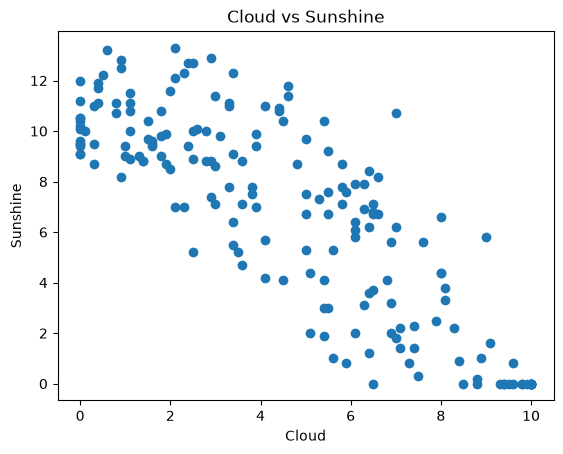

In [3]:
#시각화 코드(1), 구름량과 일조량의 관계 산점도
plt.scatter(weather['cloud'], weather['sunshine'])
plt.xlabel('Cloud')
plt.ylabel('Sunshine')
plt.title('Cloud vs Sunshine')
plt.show()


STEP 2-2. 특성변수 후보와 목표변수의 관계 시각화하기(2)


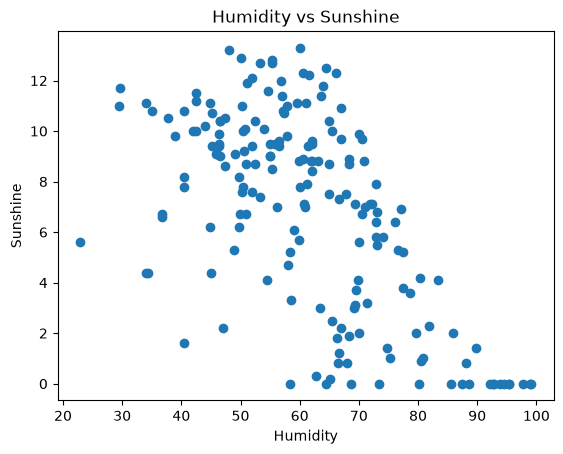

In [4]:
#시각화 코드(2), 습도와 일조량의 관계 산점도
plt.scatter(weather['humi'], weather['sunshine'])
plt.xlabel('Humidity')
plt.ylabel('Sunshine')
plt.title('Humidity vs Sunshine')
plt.show()

STEP3. 입력 데이터 X와 정답 y 정하기

In [5]:
X = weather[['temp', 'humi']]
y = weather['sunshine']
print(X.head())
print(y.head())

            temp  humi
date                  
2023-01-01  -0.2  55.0
2023-01-02  -4.5  46.0
2023-01-03  -5.0  49.0
2023-01-04  -1.8  51.0
2023-01-05  -1.6  58.1
date
2023-01-01    9.0
2023-01-02    9.1
2023-01-03    9.1
2023-01-04    8.7
2023-01-05    4.7
Name: sunshine, dtype: float64


STEP4. 훈련데이터와 테스트테이터로 분리하기

In [6]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.3, random_state=42
)
print('훈련데이터: ', X_train.shape)
print('테스트데이터: ', X_test.shape)

훈련데이터:  (126, 2)
테스트데이터:  (55, 2)


STEP5. 모델1: 선형회귀 모델 학습하기

In [8]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[ 0.05,-0.16]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['temp','humi']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,15.85
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


STEP6. 모델1: 테스트 데이터 예측하기

In [9]:
pred=model.predict(X_test)
result = pd.DataFrame({
    'original_index': y_test.index,
    'actual': y_test.values,
    'predicted': pred
})
print(result.head(10))

  original_index  actual  predicted
0     2023-01-20     8.7   7.478789
1     2023-02-12     2.0   5.092571
2     2023-06-03    13.3   7.599458
3     2023-03-20    10.0   8.461982
4     2023-05-26    10.7   7.990343
5     2023-01-16     8.8   5.737110
6     2023-01-25     9.4   8.201605
7     2023-03-10     9.6   6.841468
8     2023-04-24     7.8  10.340396
9     2023-04-29     0.8   2.759079


STEP7. 모델1: 성능 평가하기

In [10]:
from sklearn.metrics import mean_absolute_error, r2_score
mae = mean_absolute_error(y_test,pred)
r2 = r2_score(y_test,pred)
print("선형회귀 MAE: ", mae)
print("선형회귀 R2: ", r2)

선형회귀 MAE:  2.4559787343870965
선형회귀 R2:  0.4657736369806934


STEP8. 모델2: 랜덤포레스트 학습, 예측, 성능평가 (STEP5~7 모델명만 바꿔서 학습)

In [11]:
from sklearn.ensemble import RandomForestRegressor
#1. 랜텀포레스트 모델 학습하기
rf_model = RandomForestRegressor(n_estimators=1000, random_state=42)
rf_model.fit(X_train, y_train)
#2. 데스트 데이터 예측하기
rf_pred = rf_model.predict(X_test)
#3. 랜덤포레스트 성능 평가하기
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred)

print('랜텀포레스트 MAE: ', rf_mae)
print('랜텀포레스트 R2: ', rf_r2)

랜텀포레스트 MAE:  2.0845909090909034
랜텀포레스트 R2:  0.5071253455544532


STEP9. 모델1과 모델2: 성능비교

In [12]:
print("선형회귀 MAE: ", mae)
print("선형회귀 R2: ", r2)
print()
print('랜텀포레스트 MAE: ', rf_mae)
print('랜텀포레스트 R2: ', rf_r2)

선형회귀 MAE:  2.4559787343870965
선형회귀 R2:  0.4657736369806934

랜텀포레스트 MAE:  2.0845909090909034
랜텀포레스트 R2:  0.5071253455544532


STEP10. 성능 평가 결과로 모델 선정, 실제값과 예측값 시각화하기

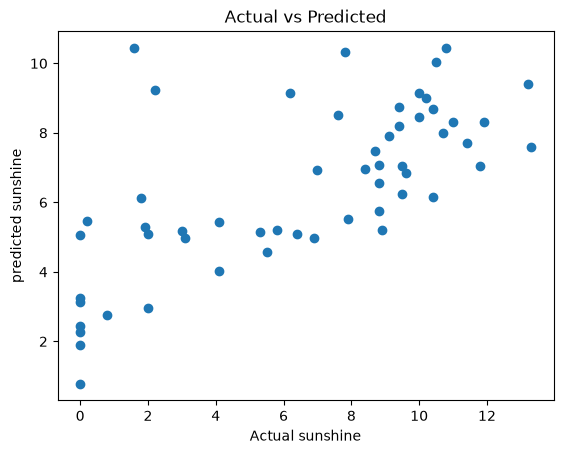

In [13]:
plt.scatter(y_test, pred)
plt.xlabel('Actual sunshine')
plt.ylabel('predicted sunshine')
plt.title('Actual vs Predicted')
plt.show()

STEP 11. 새로운 날씨 데이터 예측하기
 - X값 중 하나 이상을 바꾸어 새로운 날씨의 일조 시간 예측

In [14]:
new_weather = pd.DataFrame(
    {'temp':[20.0],
     'wind': [2.5],
     'humi': [60.0],
     'cloud': [4.0]
    }
)

new_pred = model.predict(new_weather)
print('예측 일조 시간: ', new_pred[0])


ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- cloud
- wind


<회귀 모델 성능지표 해석>

MAE: 작을수록 좋음 (실제값과 예측값이 평균적으로 얼마나 차이 나는지?)

R²: 1에 가까울수록 좋음 (모델이 실제 데이터의 변화를 얼마나 잘 설명하는지?)